# Trabajo Práctico Especial: Análisis de Datos Inside Airbnb (Buenos Aires 2026)

## 1. Análisis Exploratorio Inicial de la Base

### 1.1. Origen, Alcance y Naturaleza de los Datos
* **Fuente de datos (Secundaria):** Los datos provienen de *Inside Airbnb*, un proyecto independiente que extrae información pública de la plataforma Airbnb mediante técnicas de *web scraping*. Al ser recolectados por terceros sin control directo sobre el proceso de muestreo original, constituyen una fuente secundaria que requiere un análisis de calidad.
* **Temporalidad y Alcance:** El dataset representa un corte transversal (*snapshot*) de la oferta de alquileres temporarios publicados en la Ciudad Autónoma de Buenos Aires (CABA) en 2026. 
* **Confiabilidad y Calidad de los Datos:** Al tratarse de una plataforma donde los anfitriones ingresan los datos de sus anuncios a mano, la base es altamente susceptible a errores humanos. 
### 1.2. Criterios de Exclusión y Reducción Dimensional 
El dataset original constaba de 90 columnas. Para focalizar el análisis exploratorio y evitar ruido estadístico, se descartaron 62 variables agrupadas bajo los siguientes criterios metodológicos:

* **Variables Totalmente Nulas:** Atributos con 0 valores no nulos en el corte temporal de CABA (ej. `host_response_rate`, `neighbourhood_group_cleansed`, `instant_bookable`, `host_acceptance_rate`).
* **Metadatos, URLs e Identificadores Internos:** Enlaces a perfiles/fotos, IDs de extracción y timestamps del *scraper* (ej. `listing_url`, `scrape_id`, `picture_url`, `last_scraped`). No aportan capacidad explicativa al modelo de negocio.
* **Redundancia y Alta Multicolinealidad:** 
  * Temporalidad: Se descartaron las variables expresadas en meses (ej. `hosts_time_as_host_months`) dado que se conservó su equivalente exacto en años.
  * Disponibilidad y Reseñas: Se eliminaron ventanas temporales cortas (`availability_30`, `number_of_reviews_l30d`) en favor de las variables anualizadas (`availability_365`, `number_of_reviews_ltm`).
  * Calificaciones: Se suprimieron las subcategorías de puntuación (limpieza, comunicación, ubicación) para evitar multicolinealidad, conservando únicamente el promedio general (`review_scores_rating`).
  * Inventario del anfitrión: Se eliminó el desglose específico (`_entire_homes`, `_private_rooms`), reteniendo solo el total (`calculated_host_listings_count`).
* **Texto Libre Inestructurado:** Descripciones narrativas o comerciales (`name`, `description`, `host_about`) que requerirían procesamiento de lenguaje natural (NLP).
* **Varianza Cercana a Cero / Constantes:** Variables como `has_availability` (casi 100% de la base comparte el mismo valor) o `license` (apenas 486 datos válidos sobre 29.685), las cuales no otorgan poder discriminatorio estadístico.

### 1.3. Descricion de las variables
* **`id`**: Identificador único de la publicación. int64 
* **`host_name`**: Nombre de pila del anfitrión.str
* **`hosts_time_as_user_years`**: Años de antigüedad en la plataforma como usuario. int64
* **`hosts_time_as_host_years`**: Años de experiencia operando como anfitrión. int64
* **`host_is_superhost`**: Etiqueta (verdadero/falso) que indica si el anfitrión tiene la medalla "Superhost". str
* **`neighbourhood_cleansed`**: Nombre del barrio oficial y validado estandarizadamente. str
* **`latitude`**: coordenada latitud. float64
* **`longitude`**: coordenada longitud. float64
* **`property_type`**: Tipo arquitectónico o específico de propiedad (ej. Cabaña, Loft, Departamento).  str
* **`accommodates`**: Capacidad máxima de huéspedes que pueden dormir en la propiedad. int64. Esta limitada a 16 por airbnb
* **`bathrooms`**: Cantidad numérica total de baños. float64
* **`bedrooms`**: Cantidad total de habitaciones.  float64
* **`amenities`**: Listado de todos los servicios y comodidades incluidos (Wifi, aire acondicionado, etc.). str
* **`price`**: Precio base diario del alquiler en formato texto (suele incluir símbolo de moneda). str
* **`minimum_nights`**: Cantidad mínima de noches exigida de forma general para poder reservar. float64
* **`maximum_nights`**: Cantidad máxima de noches permitida de forma general. Cuantitativa discreta. float64
* **`availability_365`**: Cantidad de días disponibles para reservar en los próximos 365 días. int64
* **`number_of_reviews_ltm`**: Cantidad de reseñas recibidas exclusivamente en los últimos 12 meses. int64
* **`estimated_occupancy_l365d`**: Cálculo estimado de la cantidad de días que la propiedad estuvo ocupada en el último año.int64
* **`estimated_revenue_l365d`**: Cálculo estimado de los ingresos económicos brutos generados en el último año. float64
* **`review_scores_rating`**: Puntaje promedio general del anuncio otorgado por los huéspedes. float64
* **`calculated_host_listings_count`**: Cantidad de anuncios totales del anfitrión limitados a esta misma ciudad/región. int64
* **`reviews_per_month`**: Frecuencia promedio mensual con la que la propiedad recibe reseñas. float64

### 1.4. Caracterización de los Atributos Seleccionados
Seleccionamos un subconjunto de 28 variables:

**A. Variables Cualitativas (Categóricas)**
* **Nominales:** `id` (estadísticamente nominal, opera como etiqueta), `host_name`, `neighbourhood_cleansed`, `property_type`, `amenities`.
* **Dicotómicas:** `host_is_superhost`.

**B. Variables Cuantitativas (Numéricas)**
* **Discretas:** `hosts_time_as_user_years`, `hosts_time_as_host_years`, `accommodates`, `bedrooms`, `minimum_nights`, `maximum_nights`, `availability_365`, `number_of_reviews_ltm`, `estimated_occupancy_l365d`, `calculated_host_listings_count`.
* **Continuas:** `latitude`,`longitude`,`bathrooms`, `price`, `estimated_revenue_l365d`, `review_scores_rating`, `reviews_per_month`.

In [65]:
import pandas as pd

ruta_archivo = "listings (1).csv.gz"

df_listings = pd.read_csv(ruta_archivo, compression='gzip', low_memory=False)
print(f"Dimensiones del dataset: {df_listings.shape}")
df_listings.info()

Dimensiones del dataset: (29685, 90)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29685 entries, 0 to 29684
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            29685 non-null  int64  
 1   listing_url                                   29685 non-null  object 
 2   scrape_id                                     29685 non-null  int64  
 3   last_scraped                                  29685 non-null  object 
 4   source                                        29685 non-null  object 
 5   name                                          29685 non-null  object 
 6   description                                   28917 non-null  object 
 7   neighborhood_overview                         0 non-null      float64
 8   picture_url                                   29684 non-null  object 
 9   host_id                 

In [66]:
columnas_tpe = [
    'id', 'host_name', 'hosts_time_as_user_years', 'hosts_time_as_host_years', 
    'host_is_superhost', 'neighbourhood_cleansed','latitude', 'longitude', 
    'property_type', 'accommodates', 'bathrooms', 'bedrooms', 'amenities', 
    'price', 'minimum_nights', 'maximum_nights', 'availability_365', 
    'number_of_reviews_ltm', 'estimated_occupancy_l365d', 'estimated_revenue_l365d', 
    'review_scores_rating', 'calculated_host_listings_count', 'reviews_per_month'
]
df_copia = df_listings.copy()
df_copia = df_listings[columnas_tpe]
df_copia.describe()

,id,hosts_time_as_user_years,hosts_time_as_host_years,latitude,longitude,accommodates,bathrooms,bedrooms,minimum_nights,maximum_nights,availability_365,number_of_reviews_ltm,estimated_occupancy_l365d,estimated_revenue_l365d,review_scores_rating,calculated_host_listings_count,reviews_per_month
count,2.968500e+04,29685.000000,29685.000000,29685.000000,29685.000000,29685.000000,26244.000000,24500.000000,29682.000000,29682.000000,29685.000000,29685.000000,29685.000000,2.788800e+04,25957.000000,29685.000000,25957.000000
mean,9.329954e+17,7.506687,5.323362,-34.592114,-58.416274,2.941654,1.244494,1.354612,4.951722,563.329897,235.017147,12.602998,74.495873,9.570563e+06,4.780634,15.194240,1.481166
std,5.838355e+17,4.083517,4.046868,0.017920,0.030180,1.584278,0.703987,0.914463,18.114840,430.722323,116.160445,18.157164,82.642132,2.162264e+07,0.357190,32.782011,1.640487
min,1.150800e+04,0.000000,0.000000,-34.690056,-58.530890,1.000000,0.500000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000e+00,1.000000,1.000000,0.010000
25%,6.233293e+17,4.000000,2.000000,-34.603396,-58.435972,2.000000,1.000000,1.000000,1.000000,364.000000,148.000000,1.000000,6.000000,5.360180e+05,4.730000,1.000000,0.370000
50%,1.046350e+18,8.000000,4.000000,-34.591459,-58.418430,2.000000,1.000000,1.000000,2.000000,365.000000,264.000000,5.000000,42.000000,4.455030e+06,4.870000,3.000000,0.980000
75%,1.431417e+18,11.000000,8.000000,-34.581430,-58.390620,4.000000,1.000000,1.000000,3.000000,1125.000000,343.000000,18.000000,120.000000,1.316291e+07,4.980000,12.000000,2.050000
max,1.717830e+18,17.000000,15.000000,-34.534980,-58.355530,16.000000,22.000000,31.000000,730.000000,3659.000000,365.000000,581.000000,255.000000,1.285326e+09,5.000000,208.000000,41.660000


# 2. Limpieza y preparación de la base

**Objetivo de esta sección:** implementar las operaciones de limpieza necesarias sobre la base, detallando las acciones correctivas aplicadas y justificando cada una.

**Estructura del notebook**
1. Carga y copia de trabajo
2. Variables binarias del anfitrión (`t`/`f` → booleano)
3. Valores faltantes en la configuración física (`bathrooms`, `bedrooms`, `beds`)
4. Transformación de `amenities` (filtro por varianza + One-Hot Encoding)
5. Variable objetivo `price` (nulos y conversión a numérico)
6. Eliminación de filas con nulos en variables de estadía e ingresos
7. Tratamiento de outliers y de variables de reseñas *(pendiente de confirmar)*
8. Verificación final y resumen de las variables

## Resumen de la limpieza
| Problema | Variables | Acción |
|---|---|---|
| Texto `t`/`f` | `host_is_superhost` | Conversión a booleano |
| Nulos en estructura física | `bathrooms`, `bedrooms` | Imputación condicional en cascada (mediana por grupo) |
| Variable multivaluada | `amenities` | Filtro por varianza + One-Hot de 6 comodidades (`has_*`) |
| Nulos y formato en variable objetivo | `price` | *Listwise deletion* + conversión a `float` |
| Nulos marginales | `minimum_nights`, `maximum_nights`, `estimated_revenue_l365d` | Eliminación de filas |
| Valores extremos | `maximum_nights`, `number_of_reviews_ltm`, `calculated_host_listings_count` | Winsorización al percentil 99 *(a confirmar)* |
| Nulos por falta de historial | `review_scores_rating`, `reviews_per_month` | Imputación por mediana *(a confirmar)* |
| Sin problemas | `id`, `host_name`, `hosts_time_as_user_years`, `hosts_time_as_host_years`, `neighbourhood_cleansed`, `latitude`, `longitude`, `property_type`, `accommodates`, `availability_365`, `estimated_occupancy_l365d` | No se modificaron |

## 2.1. Carga y copia de trabajo
Trabajamos sobre una copia (`df_copia`) para conservar la base original intacta.

In [67]:
import numpy as np
df_copia.shape

(29685, 23)

## 2.2 Variables binarias del anfitrión
**Variables:** `host_is_superhost`

**Acción:** los valores originales eran texto (`'t'` / `'f'`). Se convirtieron a tipo booleano (`True` / `False`).

**Justificación:** son variables dicotómicas; el tipo booleano es más eficiente en memoria, evita errores de comparación entre strings y es el formato esperado por la mayoría de los métodos estadísticos y de modelado.

In [68]:
df_copia = df_copia.copy()
mapa_tf = {'t': True, 'f': False}

df_copia['host_is_superhost'] = df_copia['host_is_superhost'].map(mapa_tf)

df_copia['host_is_superhost'].value_counts()

host_is_superhost
False    17492
True     12193
Name: count, dtype: int64

## 2.3. Valores faltantes en la configuración física
**Variables:** `bathrooms`, `bedrooms`

### 2.3.1. Diagnóstico y mecanismo de pérdida
Se detectaron aproximadamente 3.000 nulos en `bathrooms`. Se descartó que los datos falten de forma completamente aleatoria (MCAR): se asume un mecanismo ***Missing At Random* (MAR)**, ya que la cantidad de baños esperada está directamente relacionada con la capacidad máxima de la propiedad (`accommodates`).

### 2.3.2. Decisión metodológica
* Se descartó **eliminar filas** para no perder ~10% de la muestra.
* Se descartó la **imputación global** (media/mediana de toda la columna), porque introduce valores constantes que atenúan artificialmente la variabilidad y las correlaciones.
* Se aplicó una **imputación condicional**: los nulos se reemplazan por la mediana del subgrupo de propiedades con igual capacidad. Así se rescatan los registros minimizando el impacto sobre la varianza y preservando la forma de la distribución.

### 2.3.3. Imputación condicinal
El orden refleja la dependencia real de un alojamiento y evita violar dependencias lógicas:
1. **Atributo raíz:** `accommodates` (capacidad máxima) es la variable independiente principal.
2. **Espacios:** `bathrooms` y `bedrooms` se imputan con la mediana por `accommodates`.


In [69]:
df_copia = df_copia.copy()
df_copia['bathrooms'] = df_copia['bathrooms'].fillna(
    df_copia.groupby('accommodates')['bathrooms'].transform('median'))
df_copia['bedrooms'] = df_copia['bedrooms'].fillna(
    df_copia.groupby('accommodates')['bedrooms'].transform('median'))

df_copia[['bathrooms', 'bedrooms']].isnull().sum()

bathrooms    0
bedrooms     0
dtype: int64

## 2.4. Transformación de `amenities`
**Variables generadas:** `has_refrigerator`, `has_bed_linens`, `has_elevator`, `has_parking`, `has_balcony_patio`, `has_pool`  
**Variable eliminada:** `amenities` (texto multivaluado original)

### 2.4.1. Enfoque descartado
Seleccionar las 5 comodidades más frecuentes por conteo absoluto presentaba dos problemas:
1. **Redundancia y multicolinealidad:** `Dishes and silverware`, `Cooking basics` o `Refrigerator` están casi directamente asociados a `Kitchen`, duplicando información.
2. **Bajo valor de negocio:** atributos triviales de alta frecuencia (`Hangers`, `Hot water`) no explican la variación de tarifas ni de demanda.

### 2.4.2. Exploración de frecuencias
Se limpió el formato de la lista (corchetes, comillas) y se midió el porcentaje de propiedades que posee cada comodidad agrupada mediante expresiones regulares.

In [70]:
# Frecuencia absoluta de cada comodidad individual
amenities_limpios = (df_copia['amenities']
                     .str.replace(r'\[|\]|"|\'', '', regex=True)
                     .str.split(r',\s*'))
conteo_amenities = amenities_limpios.explode().value_counts()
print("--- Top 15 amenities más frecuentes ---")
print(conteo_amenities.head(15))

--- Top 15 amenities más frecuentes ---
amenities
Kitchen                  27510
Wifi                     26707
Hot water                24117
Dishes and silverware    22694
Cooking basics           22002
Hangers                  21650
Bed linens               21637
Air conditioning         19969
Hair dryer               19805
Refrigerator             19448
Microwave                18608
TV                       18516
Bidet                    18301
Essentials               18170
Elevator                 17830
Name: count, dtype: int64


In [71]:
# Porcentaje de presencia por macro-categoría (regex)
patrones_amenities = {
    'Wifi / Internet': 'Wifi|Internet',
    'Kitchen (Cocina)': 'Kitchen',
    'TV (Cualquier tipo)': 'TV',
    'Air conditioning (AC)': 'Air conditioning|AC',
    'Hot water': 'Hot water',
    'Bed linens': 'Bed linens',
    'Refrigerator': 'Refrigerator',
    'Pool (Pileta)': 'Pool',
    'Parking (Estacionamiento)': 'Parking',
    'Gym (Gimnasio)': 'Gym',
    'Elevator (Ascensor)': 'Elevator',
    'Balcony / Patio': 'Balcony|Patio|Terrace|Backyard'
}

resultados = {nombre: df_copia['amenities'].str.contains(patron, case=False, na=False, regex=True).mean() * 100
              for nombre, patron in patrones_amenities.items()}

df_porcentajes = (pd.DataFrame(list(resultados.items()), columns=['Amenity_Agrupado', 'Porcentaje (%)'])
                  .sort_values(by='Porcentaje (%)', ascending=False)
                  .reset_index(drop=True))
display(df_porcentajes.round(2))

,Amenity_Agrupado,Porcentaje (%)
0,Wifi / Internet,99.14
1,Air conditioning (AC),97.47
2,Kitchen (Cocina),94.52
3,TV (Cualquier tipo),92.22
4,Hot water,82.68
5,Refrigerator,73.68
6,Bed linens,72.89
7,Elevator (Ascensor),60.06
8,Parking (Estacionamiento),55.94
9,Balcony / Patio,51.80


### 2.4.3. Filtro por varianza y One-Hot Encoding
Para no generar un dataset excesivamente esparso, no se codificaron todas las categorías: se aplicó un **filtro por varianza**.

* **Descartadas (varianza cercana a cero):** `Wifi` (>99%), `Air conditioning` (>97%), `Kitchen` (>94%) y `TV` (>92%). Al estar presentes en casi toda la oferta se comportan como constantes: su entropía es mínima y no aportan información para diferenciar propiedades ni justificar precios.
* **Conservadas:** `Refrigerator`, `Bed linens`, `Elevator`, `Parking`, `Balcony/Patio` y `Pool`, cuya presencia es intermedia. En ese rango la varianza y la entropía son altas, lo que da poder discriminatorio para segmentar el mercado.
* **Transformación:** las 6 comodidades se convirtieron en **variables dicotómicas (1/0)** mediante regex y se eliminó la columna original.

In [72]:
df_copia = df_copia.copy()
amenities_seleccionados = {
    'has_refrigerator': 'Refrigerator',
    'has_bed_linens': 'Bed linens',
    'has_elevator': 'Elevator',
    'has_parking': 'Parking',
    'has_balcony_patio': 'Balcony|Patio|Terrace|Backyard',
    'has_pool': 'Pool'
}

for col_name, pattern in amenities_seleccionados.items():
    df_copia[col_name] = (df_copia['amenities']
                          .str.contains(pattern, case=False, na=False, regex=True)
                          .astype(int))

# Se elimina la columna de texto original
df_copia = df_copia.drop(columns=['amenities'])
df_copia.describe()

,id,hosts_time_as_user_years,hosts_time_as_host_years,latitude,longitude,accommodates,bathrooms,bedrooms,minimum_nights,maximum_nights,...,estimated_revenue_l365d,review_scores_rating,calculated_host_listings_count,reviews_per_month,has_refrigerator,has_bed_linens,has_elevator,has_parking,has_balcony_patio,has_pool
count,2.968500e+04,29685.000000,29685.000000,29685.000000,29685.000000,29685.000000,29685.000000,29685.000000,29682.000000,29682.000000,...,2.788800e+04,25957.000000,29685.000000,25957.000000,29685.000000,29685.000000,29685.000000,29685.000000,29685.000000,29685.000000
mean,9.329954e+17,7.506687,5.323362,-34.592114,-58.416274,2.941654,1.224583,1.295520,4.951722,563.329897,...,9.570563e+06,4.780634,15.194240,1.481166,0.736837,0.728887,0.600640,0.559407,0.518039,0.269261
std,5.838355e+17,4.083517,4.046868,0.017920,0.030180,1.584278,0.672056,0.844914,18.114840,430.722323,...,2.162264e+07,0.357190,32.782011,1.640487,0.440358,0.444542,0.489775,0.496467,0.499683,0.443583
min,1.150800e+04,0.000000,0.000000,-34.690056,-58.530890,1.000000,0.500000,0.000000,1.000000,1.000000,...,0.000000e+00,1.000000,1.000000,0.010000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,6.233293e+17,4.000000,2.000000,-34.603396,-58.435972,2.000000,1.000000,1.000000,1.000000,364.000000,...,5.360180e+05,4.730000,1.000000,0.370000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1.046350e+18,8.000000,4.000000,-34.591459,-58.418430,2.000000,1.000000,1.000000,2.000000,365.000000,...,4.455030e+06,4.870000,3.000000,0.980000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
75%,1.431417e+18,11.000000,8.000000,-34.581430,-58.390620,4.000000,1.000000,1.000000,3.000000,1125.000000,...,1.316291e+07,4.980000,12.000000,2.050000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
max,1.717830e+18,17.000000,15.000000,-34.534980,-58.355530,16.000000,22.000000,31.000000,730.000000,3659.000000,...,1.285326e+09,5.000000,208.000000,41.660000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## 2.5. Variable objetivo `price`
### 2.5.1. Nulos
Se detectaron **1.792 nulos**. Al ser la variable objetivo del análisis de mercado, se descartó cualquier técnica de imputación (mediana, regresión, KNN) para no introducir sesgos artificiales en su distribución. Se **eliminaron las filas** afectadas: se asume una pérdida de información menor a cambio de preservar la autenticidad de la métrica financiera.

### 2.5.2. Conversión a numérico
El precio estaba almacenado como texto con símbolo `$` y separador de miles. Se eliminaron esos caracteres con regex y se convirtió a `float`, necesario para cualquier operación aritmética o estadística.

### 2.5.3 Eliminación de filas con nulos en estadía e ingresos
**Variables:** `minimum_nights`, `maximum_nights`, `estimated_revenue_l365d`

**Acción:** se eliminaron las filas con nulos en estas variables.

**Justificación:** la cantidad de nulos es baja y se trata de variables sin una variable auxiliar confiable para imputar. En `estimated_revenue_l365d`, además, el valor deriva de `price` y de la ocupación estimada, por lo que imputarlo generaría datos artificiales sobre una métrica financiera.

In [73]:
df_copia = df_copia.dropna(subset=['price'])
print("Nulos restantes en 'price':", df_copia['price'].isnull().sum())

df_copia['price'] = df_copia['price'].str.replace(r'[\$,]', '', regex=True).astype(float)
df_copia['price'].describe()

df_copia = df_copia.dropna(subset=['minimum_nights', 'maximum_nights'])
df_copia = df_copia.dropna(subset=['estimated_revenue_l365d'])
df_copia.shape

Nulos restantes en 'price': 0


(27885, 28)

### 2.6. Tratamiento de Outliers y Variables de Reseñas

#### 2.6.1. Eliminación de valores extremos
**Variables:** `maximum_nights`, `number_of_reviews_ltm`, `calculated_host_listings_count`
Se detectaron valores atípicos que distorsionan severamente el análisis visual y las medidas de tendencia central (ej. alojamientos con configuraciones irreales de más de 3 años de estadía máxima, o mega-agencias con cientos de propiedades). Tras verificar mediante cuantificación que los registros ubicados por encima del percentil 99 representan menos del 1% de los datos para cada variable, se procedió a **eliminar estas filas**. Esta decisión purifica la distribución para el análisis exploratorio sin comprometer la representatividad estadística de la muestra general.

#### 2.6.2. Preservación de nulos estructurales en reseñas
**Variables:** `review_scores_rating`, `reviews_per_month`
Estas variables presentan nulos que responden a una ausencia lógica de datos (propiedades nuevas o sin reservas consolidadas). Se decidió **no aplicar ninguna técnica de imputación** para mantener la fidelidad de la métrica. Alterar estos nulos inyectaría calificaciones artificiales a propiedades no probadas por el mercado, sesgando el análisis de reputación.

#### 2.6.3. Conservación de Outliers Naturales
No se aplicó recorte sobre variables financieras o estructurales fundamentales como `price` o `minimum_nights`. Los valores atípicos en estas métricas representan nichos legítimos del mercado real (propiedades de ultra lujo o alquileres de formato mensual). Su eliminación constituiría una manipulación de la muestra que ocultaría la amplitud real del mercado inmobiliario porteño; por lo tanto, se conservaron intactos en el dataset, aplicando recortes de percentiles exclusivamente para la renderización de las visualizaciones gráficas.

In [74]:
cols_outliers = ['maximum_nights', 'number_of_reviews_ltm', 'calculated_host_listings_count']

print("--- Recuento de valores extremos (> Percentil 99) ---")
for col in cols_outliers:
    umbral_99 = df_copia[col].quantile(0.99)
    cantidad_outliers = (df_copia[col] > umbral_99).sum()
    porcentaje = (cantidad_outliers / len(df_copia)) * 100
    print(f"{col}: {cantidad_outliers} registros ({porcentaje:.2f}%) por encima del valor {umbral_99:.2f}")

--- Recuento de valores extremos (> Percentil 99) ---
maximum_nights: 12 registros (0.04%) por encima del valor 1125.00
number_of_reviews_ltm: 273 registros (0.98%) por encima del valor 80.00
calculated_host_listings_count: 208 registros (0.75%) por encima del valor 186.00


In [75]:
cols_outliers = ['maximum_nights', 'number_of_reviews_ltm', 'calculated_host_listings_count']

print(f"Total de filas antes del recorte: {len(df_copia)}")

# Aplicamos un filtrado iterativo conservando solo los valores <= al percentil 99
for col in cols_outliers:
    umbral_99 = df_copia[col].quantile(0.99)
    df_copia = df_copia[df_copia[col] <= umbral_99]

print(f"Total de filas después del recorte: {len(df_copia)}")

Total de filas antes del recorte: 27885
Total de filas después del recorte: 27392


### 3. Distribución de Variables: Comportamiento y Asimetrías

Los histogramas muestran distribuciones muy alejadas de la normal. Predominan las colas largas a la derecha, los valores “redondos” por defecto de la plataforma y los picos en valores extremos. Varias variables están graficadas con zoom por percentil (p95, p98 o p99), por lo que las colas reales son más largas que lo visible.

#### 1. Variables con Fuerte Asimetría Positiva (Sesgo a la Derecha)
* **Precio e ingresos (`price`, `estimated_revenue_l365d`):** `price` tiene la moda en torno a los $80.000-$100.000 y una cola larga hacia propiedades premium (el gráfico se corta en p95, con valores de hasta $300.000). `estimated_revenue_l365d` está inflada en cero (más de 8.000 anuncios sin ingresos estimados) y decae lentamente hasta ~$30 millones anuales.
* **Capacidad (`accommodates`, `bedrooms`, `bathrooms`):** La oferta es mayormente de departamentos chicos. `accommodates` tiene la moda en 2 personas, con un segundo escalón en 4. `bedrooms` y `bathrooms` se concentran en 1, con caídas fuertes en 2, 3 y 4 o más.
* **Anfitrión y reglas (`calculated_host_listings_count`, `minimum_nights`):** Domina el anfitrión de 1 propiedad (~10.000 casos), seguido por el de 2. La cola, de hasta ~70 propiedades, corresponde a agencias e inversores. `minimum_nights` se concentra en 1 a 3 noches, con picos aislados en valores redondos (7, 15, 30), típicos del alquiler temporario y mensual.
* **Antigüedad como anfitrión (`hosts_time_as_host_years`):** Moda en 2-3 años, con muchos anfitriones nuevos (~0 años) y una cola hasta 15 años. Hay un pico secundario cerca de los 7 años.
* **Actividad (`number_of_reviews_ltm`, `reviews_per_month`):** Cerca de 10.000 anuncios no recibieron reseñas en el último año (nuevos, inactivos o poco demandados). El resto decae rápido, y casi todos están por debajo de 3 reseñas por mes.
* **Ocupación (`estimated_occupancy_l365d`):** Hay una gran masa en 0-10 días (~7.700 anuncios) y un decaimiento progresivo. Como esta variable es una estimación y no un dato observado, el pico en ~255 días no es un comportamiento real. Es consistente con el tope del 70% de ocupación (0,7 × 365 ≈ 255) que Inside Airbnb aplica en su modelo.

#### 2. Variables con Asimetría Negativa (Sesgo a la Izquierda)
* **Reputación (`review_scores_rating`):** Casi toda la masa está entre 4,5 y 5, con la moda en 5.
* **Disponibilidad (`availability_365`):** A diferencia de una bimodal clásica, el pico dominante está en 365 días (~5.400 anuncios siempre abiertos). El resto es irregular, con pequeños picos intermedios y muy poco en torno a 0. 

#### 3. Distribuciones Polarizadas o Multimodales
* **Estadía máxima (`maximum_nights`):** Concentrada en tres valores: 365 y 1125 (este último parece ser el valor por defecto de la plataforma) y, en menor medida, valores bajos (~30) y 730. Por eso tiene poca información real y se parece más a una variable categórica.
* **Antigüedad como usuario (`hosts_time_as_user_years`):** Es irregular y multimodal (picos cerca de 3 y 10 años), sin sesgo marcado. Probablemente refleja distintas “olas” de incorporación de anfitriones a la plataforma.

#### 4. Distribuciones Geográficas (Pseudo-Normales)
* **Latitud (`latitude`):** Es casi normal y se centra cerca de -34,60, con un pequeño hombro hacia el norte (zona Belgrano/Núñez).
* **Longitud (`longitude`):** Es asimétrica a la izquierda y bimodal: un pico cerca de -58,43 (corredor Palermo/Villa Crespo) y otro cerca de -58,37 (zona Centro/Puerto Madero/San Telmo). La cola izquierda corresponde a barrios más periféricos hacia el oeste.

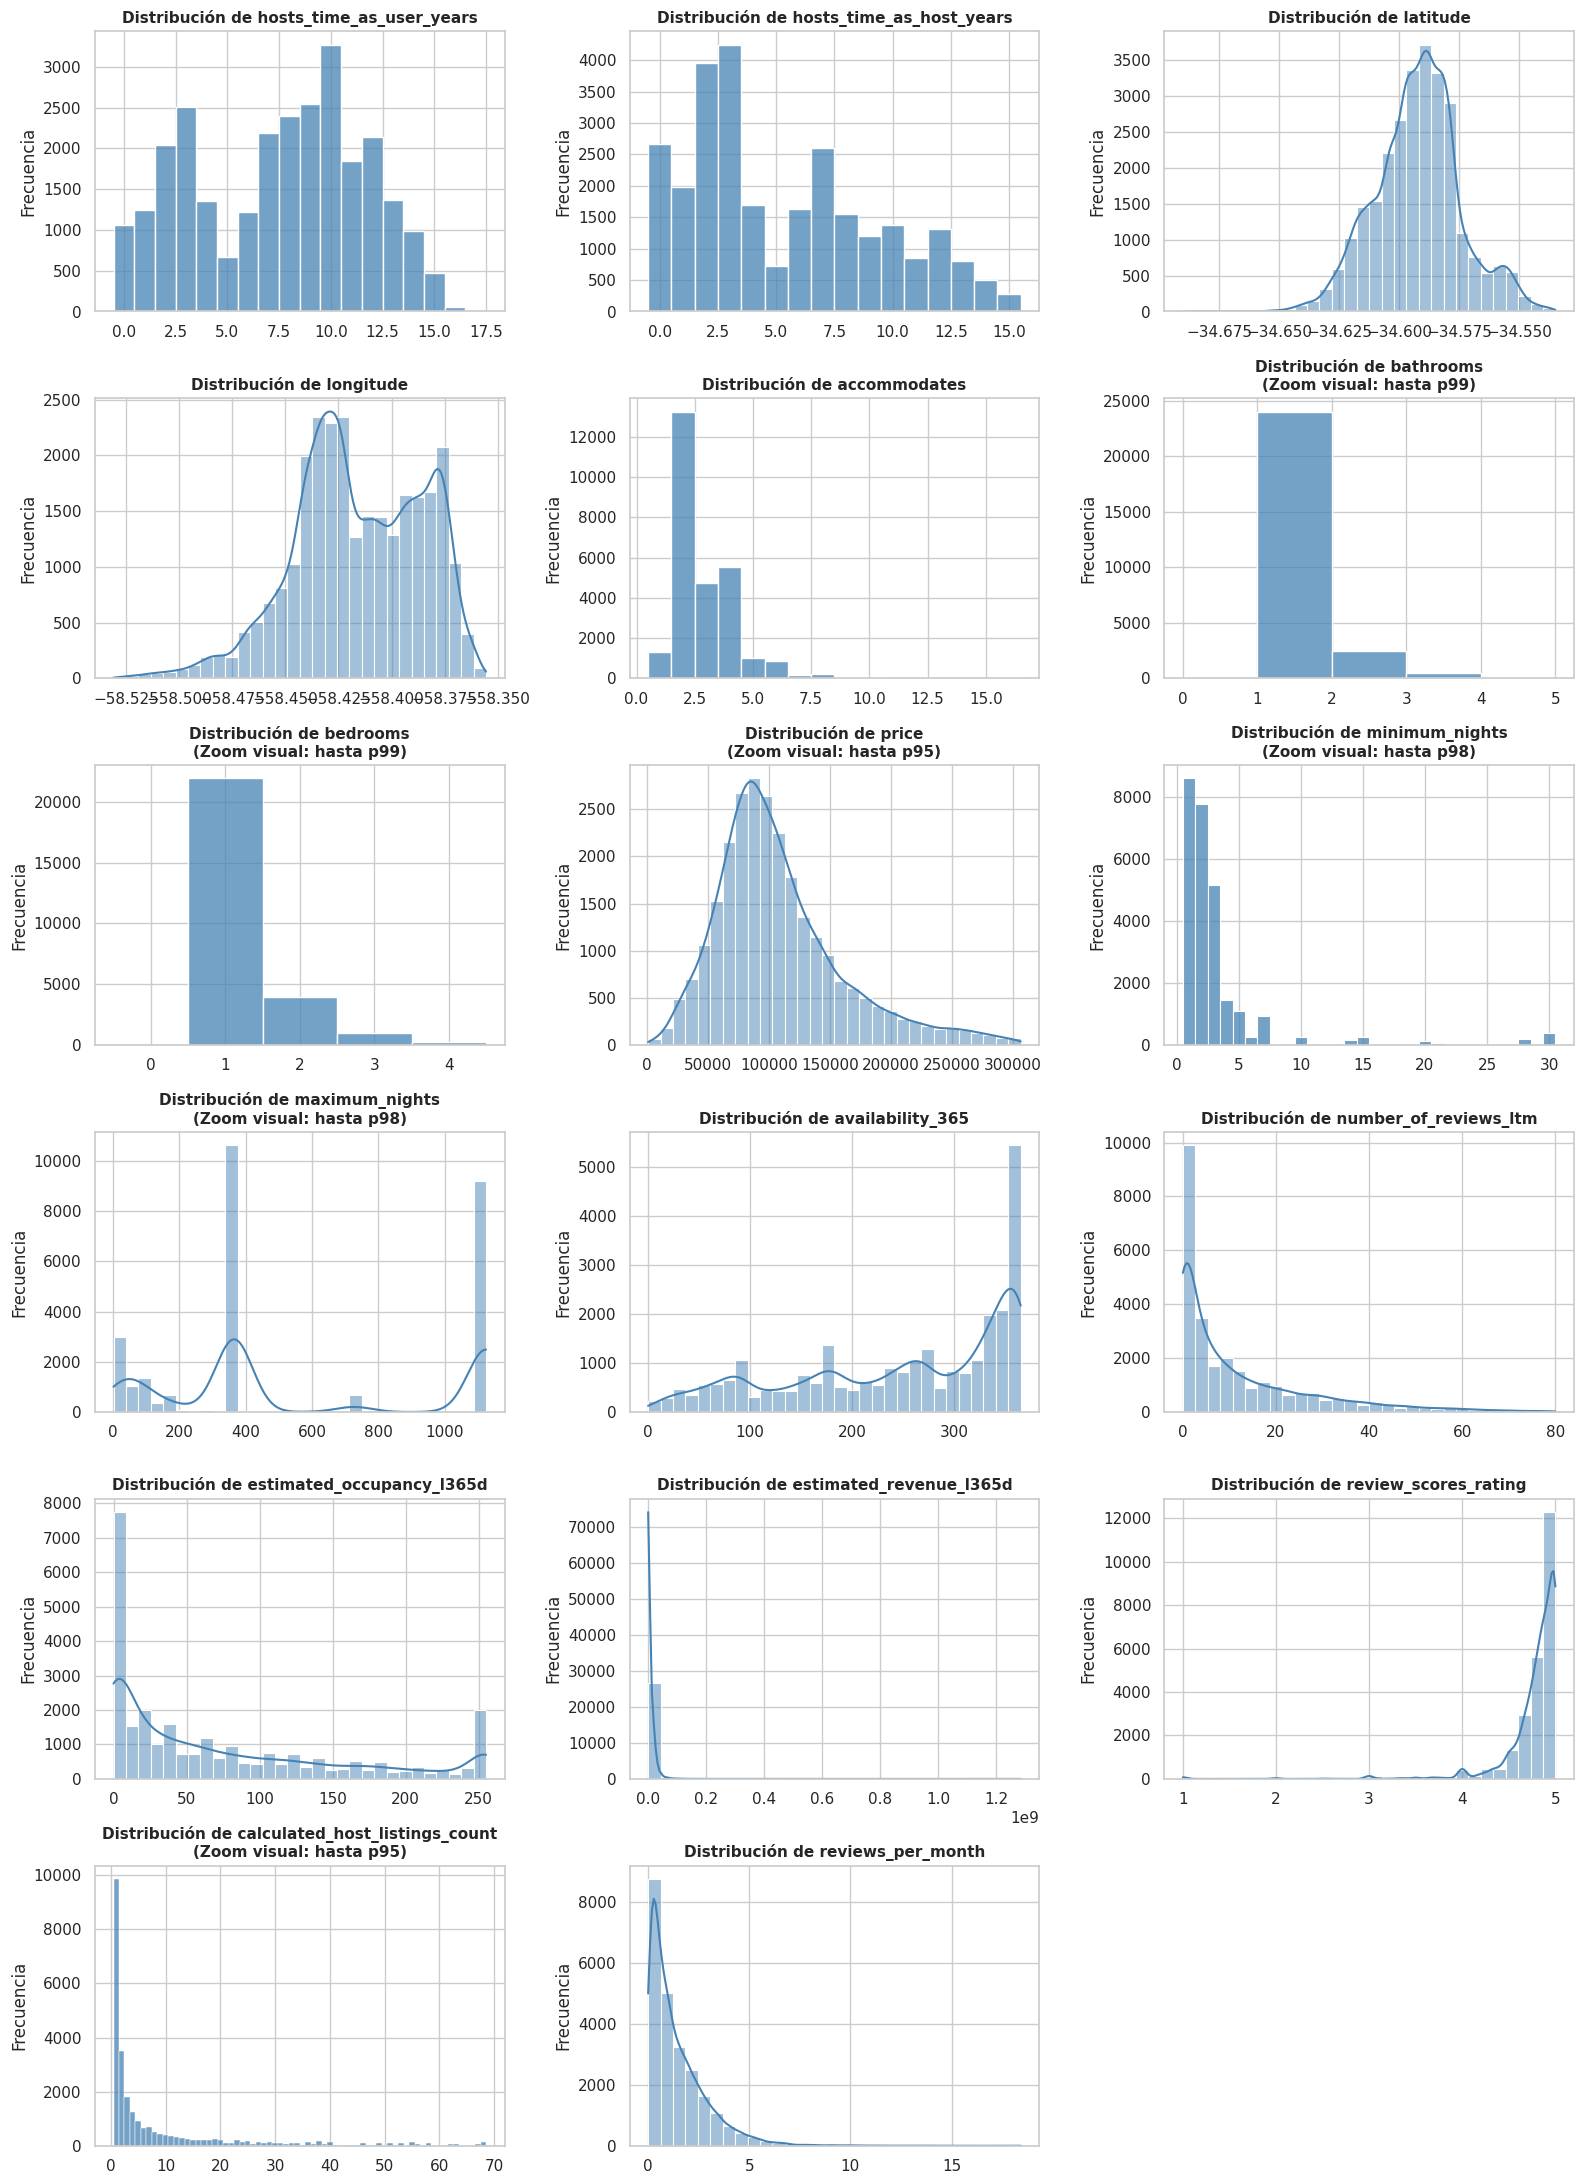

In [76]:
import matplotlib.pyplot as plt
import seaborn as sns

variables_numericas = [
    'hosts_time_as_user_years', 'hosts_time_as_host_years', 'latitude', 'longitude', 
    'accommodates', 'bathrooms', 'bedrooms', 'price', 'minimum_nights', 
    'maximum_nights', 'availability_365', 'number_of_reviews_ltm', 
    'estimated_occupancy_l365d', 'estimated_revenue_l365d', 
    'review_scores_rating', 'calculated_host_listings_count', 'reviews_per_month'
]

variables_discretas = [
    'hosts_time_as_user_years', 'hosts_time_as_host_years', 'accommodates', 
    'bathrooms', 'bedrooms', 'minimum_nights', 'calculated_host_listings_count'
]

variables_con_zoom = {
    'price': 0.95,
    'minimum_nights': 0.98,
    'maximum_nights': 0.98,
    'bathrooms': 0.99,
    'bedrooms': 0.99,
    'calculated_host_listings_count': 0.95
}

# Creamos una serie local para el precio (si es texto) sin modificar df_copia
if df_copia['price'].dtype == 'object':
    s_price = df_copia['price'].replace(r'[\$,]', '', regex=True).astype(float)
else:
    s_price = df_copia['price']

fig, axes = plt.subplots(nrows=6, ncols=3, figsize=(16, 22))
axes = axes.flatten()
sns.set_theme(style="whitegrid")

for i, col in enumerate(variables_numericas):
    if col in df_copia.columns:
        # Usamos la serie local s_price si la columna es 'price', evitando mutar df_copia
        if col == 'price':
            datos = s_price.dropna()
        else:
            datos = df_copia[col].dropna()
            
        titulo = f'Distribución de {col}'
        
        # Aplicamos el zoom visual (solo afecta al gráfico, no al DataFrame)
        if col in variables_con_zoom:
            percentil = variables_con_zoom[col]
            datos = datos[datos <= datos.quantile(percentil)]
            titulo += f'\n(Zoom visual: hasta p{int(percentil*100)})'
            
        # Lógica de graficado: Discreta vs Continua
        if col in variables_discretas:
            sns.histplot(datos, discrete=True, kde=False, ax=axes[i], color='steelblue')
        else:
            sns.histplot(datos, bins=30, kde=True, ax=axes[i], color='steelblue')
        
        axes[i].set_title(titulo, fontweight='bold', fontsize=11)
        axes[i].set_xlabel('')
        axes[i].set_ylabel('Frecuencia')

# Eliminamos los ejes sobrantes
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

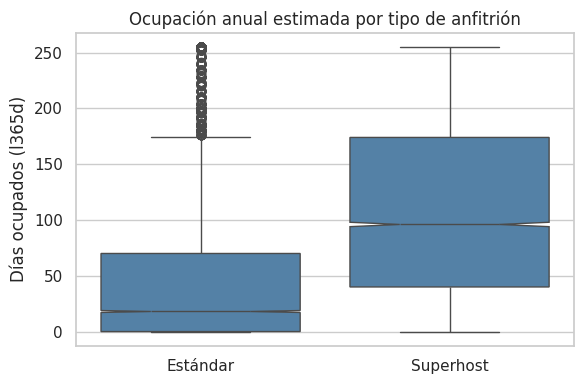

           count  median        mean
grupo                               
Estándar   15927    18.0   49.393922
Superhost  11465    96.0  110.437244
Spearman = 0.418, p-valor = 0


In [77]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

col = "estimated_occupancy_l365d"

d = df_copia[["host_is_superhost", col]].dropna().copy()
d["super_bin"] = d["host_is_superhost"].astype(int)   # True -> 1, False -> 0
d["grupo"] = d["super_bin"].map({1: "Superhost", 0: "Estándar"})

# Boxplot
plt.figure(figsize=(6, 4))
sns.boxplot(data=d, x="grupo", y=col, notch=True, order=["Estándar", "Superhost"], color="steelblue")
plt.title("Ocupación anual estimada por tipo de anfitrión")
plt.xlabel("")
plt.ylabel("Días ocupados (l365d)")
plt.tight_layout()
plt.show()

# Medianas por grupo
print(d.groupby("grupo")[col].agg(["count", "median", "mean"]))

# Spearman
rho, p = stats.spearmanr(d["super_bin"], d[col])
print(f"Spearman = {rho:.3f}, p-valor = {p:.4g}")

### 3.1. Análisis Gráfico y Descriptivo: Impacto del status Superhost

El gráfico de cajas (*boxplot* con *notches*) evidencia una disparidad rotunda en la distribución y el rendimiento de ambos segmentos del mercado:

**1. Dispersión y Rango Intercuartílico (Cajas)**
* **Anfitriones Estándar:** Su distribución está fuertemente comprimida hacia el límite inferior. El 50% central de la muestra se concentra en un rango muy estrecho, sin lograr superar los 70 días de ocupación anual.
* **Superhosts:** Presentan una caja mucho más alta (mayor dispersión), lo que indica que dentro de este grupo coexisten distintos niveles de éxito, pero operando sobre un piso y un techo muy superiores. Su 50% central rinde entre ~40 y 175 días ocupados.

**2. Análisis de las Muescas (*Notches*) e Intervalos de Confianza**
Las muescas representan el intervalo de confianza (al 95%) alrededor de la mediana:
* **Falta de solapamiento:** Las muescas de ambas cajas están a alturas completamente distintas y no se superponen en absoluto. Esta es una prueba gráfica contundente de que las medianas poblacionales de ambos grupos son significativamente diferentes.
* **Tamaño (amplitud) de las muescas:** La muesca del grupo *Estándar* es extremadamente fina y angosta. Esto ocurre por la combinación de un mayor tamaño de muestra ($n=15.927$) y una fuerte aglomeración de los datos en valores bajos (menor rango intercuartílico). Por el contrario, la muesca del grupo *Superhost* es visualmente más amplia (abierta). Esta amplitud nos indica que, al tener una mayor dispersión de datos en el centro de su distribución y un tamaño de muestra ligeramente menor ($n=11.465$), existe un intervalo de incertidumbre levemente mayor para fijar el punto exacto de la mediana poblacional.

**3. Comportamiento de los Valores Atípicos (*Outliers*)**
* El grupo *Estándar* presenta una densa cola de *outliers* (puntos por encima del bigote superior) que llegan hasta los 250 días. Esto significa que, para un anfitrión sin medalla, alcanzar una ocupación alta es estadísticamente una anomalía.
* En el grupo *Superhost*, el bigote superior se extiende naturalmente hasta abarcar esos mismos valores altos, sin que el gráfico marque ningún punto como *outlier*. Esto demuestra que lograr ocupaciones cercanas al año completo es un comportamiento estadísticamente normal y esperado para la categoría premium.

In [78]:
import numpy as np
from scipy import stats

col = "estimated_occupancy_l365d"
sup = df_copia.loc[df_copia["host_is_superhost"] == True, col].dropna()
est = df_copia.loc[df_copia["host_is_superhost"] == False, col].dropna()

# 1. Normalidad (con n grande conviene mirar también el QQ plot)
print("Shapiro Superhost:", stats.shapiro(sup.sample(5000, random_state=42)))
print("Shapiro Estándar: ", stats.shapiro(est.sample(5000, random_state=42)))

# 2. Homogeneidad de varianzas (Levene, centrado en la mediana)
print("Levene:", stats.levene(sup, est))


Shapiro Superhost: ShapiroResult(statistic=np.float64(0.9118951588734336), pvalue=np.float64(4.201004603693161e-47))
Shapiro Estándar:  ShapiroResult(statistic=np.float64(0.7268815265695505), pvalue=np.float64(1.2793815614389338e-67))
Levene: LeveneResult(statistic=np.float64(1299.6168348902154), pvalue=np.float64(4.3372898785928207e-278))


Se rechazan los supuesto de normalidad y homocedasticidad por ende se pasa a hacer el test de la mediana a una cola

In [79]:
col = "estimated_occupancy_l365d"
# Filtramos de forma segura usando .loc
sup = df_copia.loc[df_copia["host_is_superhost"] == True, col].dropna()
est = df_copia.loc[df_copia["host_is_superhost"] == False, col].dropna()

# Prueba de la Mediana (Unilateral)
print("--- PRUEBA DE LA MEDIANA ---")
chi2, p_med_bilateral, mediana_global, tabla = stats.median_test(sup, est)

# Adaptación matemática a una cola (H1: Superhost > Estándar)
if sup.median() > est.median():
    p_med_unilateral = p_med_bilateral / 2
else:
    p_med_unilateral = 1 - (p_med_bilateral / 2)

print(f"Chi2 = {chi2:.2f}")
print(f"p-valor (unilateral) = {p_med_unilateral:.4g}")
print(f"Mediana Superhost: {sup.median()} | Mediana Estándar: {est.median()}\n")

--- PRUEBA DE LA MEDIANA ---
Chi2 = 3929.42
p-valor (unilateral) = 0
Mediana Superhost: 96.0 | Mediana Estándar: 18.0



Hipótesis 1: Baja ocupación media anual de los alojamientos de Airbnb en CABA.
La ocupación anual estimada de los alojamientos de Airbnb en CABA, medida mediante estimated_occupancy_l365d, presenta una media inferior al 45 % de los últimos 365 días, equivalente a 164,25 días.<br>
Variable: estimated_occupancy_l365d. Cuantitativa discreta, días ocupados en los últimos 365. <br>

H<sub>0</sub>: μ ≥ 45% (~164 dias) <br>
H<sub>1</sub>: μ < 45% (~164 dias)

Donde μ representa la media poblacional de días de ocupación estimada
Al observar el describe, hay tres observaciones interesantes:
La media es mayor que la mediana: 74,50 frente a 42 días. Esto es compatible con una distribución asimétrica hacia la derecha, en la que algunos valores altos elevan la media.
Existe una dispersión considerable: la desviación estándar es de 82,64 días. Los valores no están concentrados cerca de la media.
La mitad de los anuncios tiene una ocupación estimada de 42 días o menos, mientras que el 25 % presenta una ocupación estimada de 120 días o más.

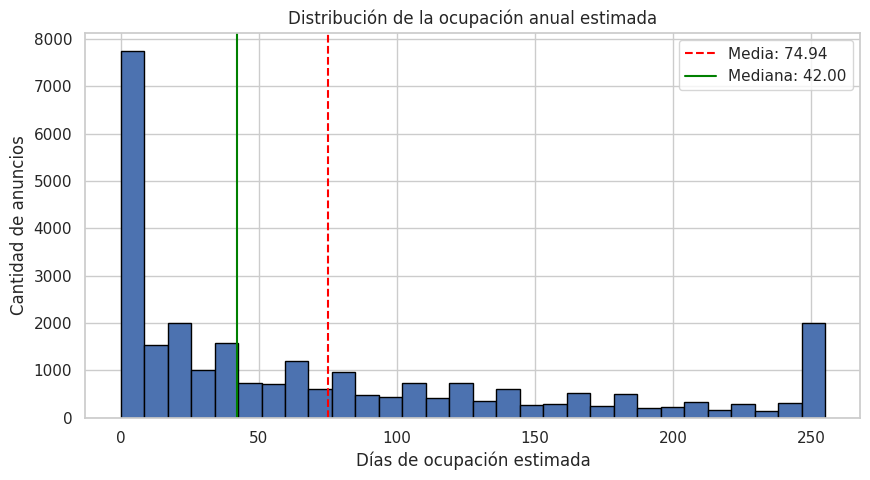

In [80]:
import matplotlib.pyplot as plt

columna_h1 = "estimated_occupancy_l365d"
x = df_copia[columna_h1].dropna()

plt.figure(figsize=(10, 5))

plt.hist(x, bins=30, edgecolor="black")

plt.axvline(x.mean(), color="red", linestyle="--", label=f"Media: {x.mean():.2f}")

plt.axvline(x.median(), color="green", linestyle="-", label=f"Mediana: {x.median():.2f}")

plt.xlabel("Días de ocupación estimada")
plt.ylabel("Cantidad de anuncios")
plt.title("Distribución de la ocupación anual estimada")
plt.legend()
plt.show()

El análisis gráfico de la variable estimated_occupancy_l365d evidencia una distribución asimétrica hacia la derecha, caracterizada por una elevada concentración de observaciones en valores bajos de ocupación y una disminución progresiva de las frecuencias a medida que aumentan los días ocupados. Se destaca, además, la presencia de un segundo pico cercano al valor máximo de la variable (255 días)

Asimismo, se observa que la media (74,50 días) supera considerablemente a la mediana (42 días), lo cual resulta consistente con la presencia de valores altos que desplazan la media hacia la derecha. En consecuencia, la distribución no presenta visualmente las características de una distribución normal.

Estadístico W: 0.8333228886772845
p-valor: 3.398303175950128e-58
Se rechaza H0: los datos no siguen una distribución normal.


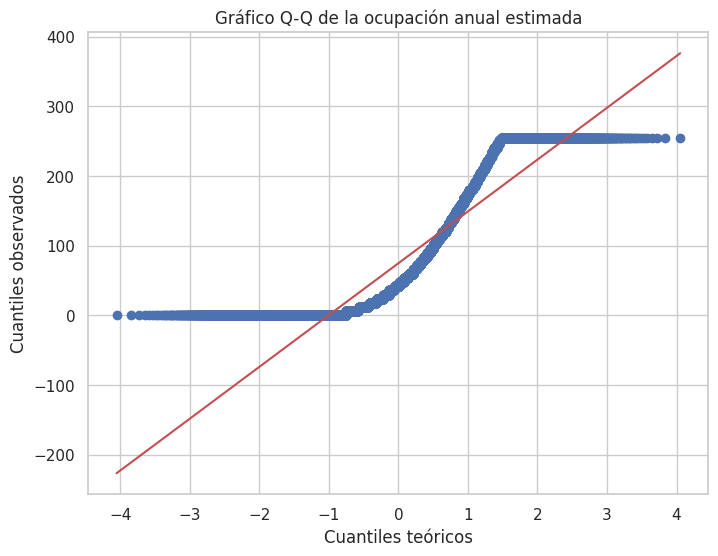

In [81]:
from scipy.stats import shapiro

#Seleccionar una muestra aleatoria de 5000 observaciones
#La implementación de Shapiro-Wilk de SciPy advierte que, para muestras superiores a 5.000, el estadístico W es válido, pero el p-valor puede no ser preciso.
muestra_h1 = x.sample(n=5000, random_state=42)

#Aplicar Shapiro-Wilk
stat, p_value = shapiro(muestra_h1)

print("Estadístico W:", stat)
print("p-valor:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Se rechaza H0: los datos no siguen una distribución normal.")
else:
    print("No se rechaza H0: no hay evidencia suficiente para descartar normalidad.")
import scipy.stats as stats

plt.figure(figsize=(8, 6))

stats.probplot(x, dist="norm", plot=plt)

plt.title("Gráfico Q-Q de la ocupación anual estimada")
plt.xlabel("Cuantiles teóricos")
plt.ylabel("Cuantiles observados")

plt.show()

Para evaluar el supuesto de normalidad, se aplicó la prueba de Shapiro-Wilk sobre una muestra aleatoria de 5.000 observaciones. Dado que el p-valor es inferior al nivel de significación establecido (α = 0,05), se rechaza la hipótesis nula de normalidad.

Este resultado se complementa con el gráfico Q-Q, en el cual se observan desviaciones pronunciadas respecto de la línea de referencia, especialmente en los extremos de la distribución. Se destaca la concentración de observaciones cercanas a cero y la presencia de un segundo agrupamiento en 255 días.

En consecuencia, se concluye que la variable no presenta una distribución normal.

In [82]:
#Valor de referencia: 45% de 365 días
umbral = 365 * 0.45

#Test t para una muestra (unilateral a izquierda)
resultado = stats.ttest_1samp(
    x,
    popmean=umbral,
    alternative="less"
)

print("Media muestral:", x.mean())
print("Valor de referencia:", umbral)
print("Estadístico t:", resultado.statistic)
print("P-valor:", resultado.pvalue)
#Para validar la hipótesis planteada, se aplicó un test t para una muestra, utilizando como valor de referencia 164,25 días, equivalentes al 45 % del año. Se estableció un nivel de significación de α = 0,05 y se realizó un contraste unilateral a izquierda.

#Los resultados obtenidos fueron una media muestral de 74,50 días, un estadístico t = -187,12 y un p-valor inferior a la precisión numérica de la herramienta utilizada.

#Dado que el p-valor es inferior al nivel de significación establecido, se rechaza la hipótesis nula. Por lo tanto, se encuentra evidencia estadística para afirmar que la media de ocupación anual estimada de los anuncios analizados es inferior a 164,25 días.

#En términos prácticos, la media observada representa aproximadamente el 20,4 % de los últimos 365 días, considerablemente por debajo del 45 % propuesto como referencia. Esto evidencia un nivel de ocupación media bajo en los anuncios incluidos en el conjunto de datos.
#Cantidad de anfitriones diferentes
print("Anfitriones únicos:", df_listings["host_id"].nunique())

#Cantidad de anuncios por anfitrión
anuncios_por_host = df_listings.groupby("host_id").size()

print("\nAnfitriones con más de un anuncio:",
      (anuncios_por_host > 1).sum())

print("\nMáxima cantidad de anuncios de un anfitrión:",
      anuncios_por_host.max())

print("\nDistribución de anuncios por anfitrión:")
print(anuncios_por_host.describe())

Media muestral: 74.94377920560747
Valor de referencia: 164.25
Estadístico t: -181.36201999745774
P-valor: 0.0
Anfitriones únicos: 14556

Anfitriones con más de un anuncio: 3748

Máxima cantidad de anuncios de un anfitrión: 208

Distribución de anuncios por anfitrión:
count    14556.000000
mean         2.039365
std          5.179714
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max        208.000000
dtype: float64


Como limitación del análisis, se identificó que algunos anfitriones poseen múltiples anuncios, lo que podría generar dependencia entre las observaciones. En consecuencia, aunque el tamaño muestral permite justificar cierta robustez del test frente a la falta de normalidad, la posible dependencia entre anuncios podría afectar la estimación del error estándar y la significación estadística obtenida. Los resultados deben interpretarse considerando esta limitación.